In [1]:
import sys
print(sys.executable)

import pandas, sklearn, xgboost
print("Librerías OK")

/home/saurin/sistema-servicios-ia/backend/venv/bin/python
Librerías OK


In [1]:
import pandas as pd

df = pd.read_csv("../data/ordenes.csv")

print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (4000, 16)


,orden_id,tipo_equipo,marca,modelo,tecnico,especialidad_tecnico,anios_experiencia,descripcion_falla,categoria_falla,prioridad,repuestos,num_repuestos,fecha_ingreso,estado,tiempo_real_dias,costo_real
0,1,laptop,Lenovo,Legion 5,Jorge Ramírez,software,5,no me abre el office ni el navegador,software,baja,NaN,0,2026-04-11 02:28,entregado,1.5,45.86
1,2,laptop,Apple,MacBook Pro 13,Miguel Salazar,hardware,1,la laptop se apaga sola cuando la desconecto,bateria,media,Batería de laptop,1,2025-10-16 04:35,entregado,2.8,268.38
2,3,pc,Lenovo,ThinkCentre M70,Miguel Salazar,hardware,1,dice que no encueentra el sistema operativo,disco_duro,alta,Disco duro HDD,1,2025-08-13 23:25,entregado,5.0,190.17
3,4,laptop,Acer,Nitro 5,Lucía Torres,hardware,3,"hola, perdi mis archivos y no abre carpetas",disco_duro,alta,Disco duro HDD,1,2025-07-01 05:33,entregado,3.7,155.95
4,5,impresora,Canon,Pixma G3110,Rosa Paredes,impresoras,2,"oiga, dice atasco de papel pero no veo nada at...",atasco_papel,media,Rodillo de arrastre,1,2025-06-12 09:36,entregado,1.7,65.83


In [2]:
terminadas = df.dropna(subset=["tiempo_real_dias", "costo_real"]).copy()

print("Ordenes totales:", len(df))
print("Ordenes terminadas (usables para entrenar):", len(terminadas))

terminadas[["tiempo_real_dias", "costo_real"]].describe()

Ordenes totales: 4000
Ordenes terminadas (usables para entrenar): 3984


,tiempo_real_dias,costo_real
count,3984.000000,3984.000000
mean,3.174398,202.627096
std,2.452567,164.151138
min,0.600000,32.820000
25%,1.700000,66.227500
50%,2.400000,162.515000
75%,3.800000,296.472500
max,28.900000,1519.230000


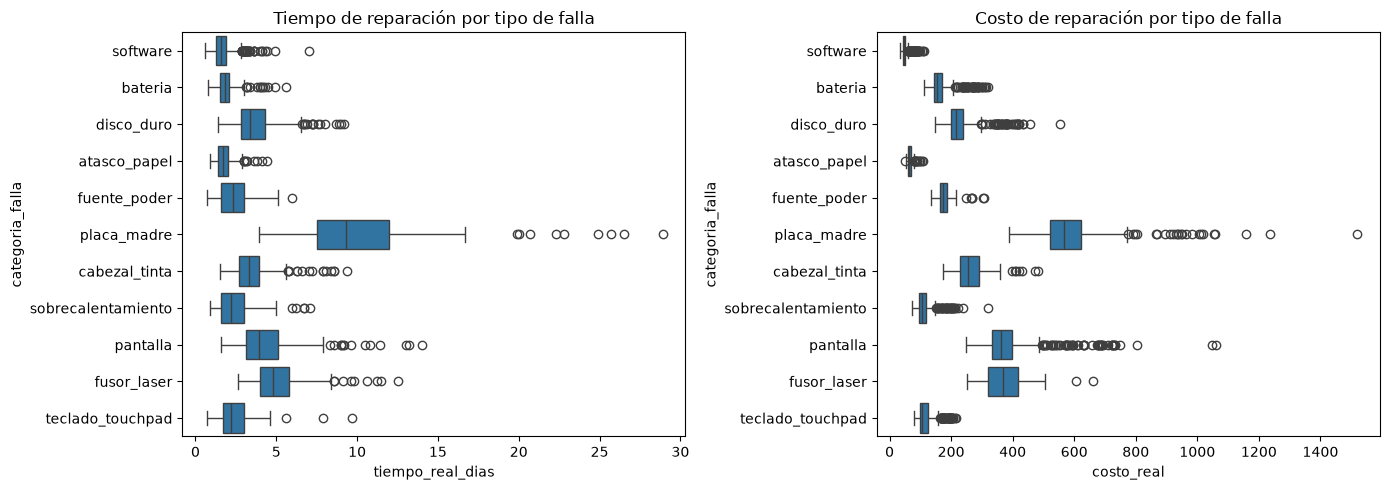

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=terminadas, x="tiempo_real_dias", y="categoria_falla", ax=ax[0])
ax[0].set_title("Tiempo de reparación por tipo de falla")

sns.boxplot(data=terminadas, x="costo_real", y="categoria_falla", ax=ax[1])
ax[1].set_title("Costo de reparación por tipo de falla")

plt.tight_layout()
plt.show()